In [1]:
%pip install -U langgraph langchain-groq

  Attempting uninstall: langgraph
    Found existing installation: langgraph 1.2.19
    Uninstalling langgraph-1.2.19:
      Successfully uninstalled langgraph-1.2.19
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [langgraph]


In [2]:
from langgraph.graph import StateGraph ,START,END
from langchain_groq import ChatGroq
from typing import TypedDict,Annotated,Literal
from langchain_core.messages import SystemMessage,HumanMessage
from pydantic import BaseModel, Field
import operator
from google.colab import userdata

In [26]:
# Retrieve Groq API key from Colab Secrets
groq_api_key = userdata.get("GROQ_API_KEY")

# Initialize the model
generator_llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
    api_key=groq_api_key
)

# Initialize the model
evaluator_llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    api_key=groq_api_key
)

# Initialize the model
optimizer_llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    api_key=groq_api_key
)

In [27]:
class TweetEvalutaion(BaseModel):
  evaluation:Literal["approved","needs_improvement"]=Field(...,description="Final evaluation result.")
  feedback:str=Field(...,description="feedback for the tweet")

In [28]:
structured_evalutator_llm=evaluator_llm.with_structured_output(TweetEvalutaion)

In [29]:
class TweetState(TypedDict):
  topic:str
  tweet:str
  evaluation:Literal["approved","needs_improvement"]
  feedback:str
  iteration:int
  max_iteration:int
  tweet_history: Annotated[list[str], operator.add]
  feedback_history: Annotated[list[str], operator.add]

In [30]:
def generate_tweet(state:TweetState):
  messages = [
        SystemMessage(content="You are a funny and clever Twitter/X influencer."),
        HumanMessage(content=f"""
Write a short, original, and hilarious tweet on the topic: "{state['topic']}".

Rules:
- Do NOT use question-answer format.
- Max 280 characters.
- Use observational humor, irony, sarcasm, or cultural references.
- Think in meme logic, punchlines, or relatable takes.
- Use simple, day to day english
""")
    ]

    # send generator_llm
  response = generator_llm.invoke(messages).content

    # return response
  return {'tweet': response, 'tweet_history': [response]}

In [31]:
def evaluate_tweet(state:TweetState):
  messages = [
    SystemMessage(content="You are a ruthless, no-laugh-given Twitter critic. You evaluate tweets based on humor, originality, virality, and tweet format."),
    HumanMessage(content=f"""
Evaluate the following tweet:

Tweet: "{state['tweet']}"

Use the criteria below to evaluate the tweet:

1. Originality – Is this fresh, or have you seen it a hundred times before?
2. Humor – Did it genuinely make you smile, laugh, or chuckle?
3. Punchiness – Is it short, sharp, and scroll-stopping?
4. Virality Potential – Would people retweet or share it?
5. Format – Is it a well-formed tweet (not a setup-punchline joke, not a Q&A joke, and under 280 characters)?

Auto-reject if:
- It's written in question-answer format (e.g., "Why did..." or "What happens when...")
- It exceeds 280 characters
- It reads like a traditional setup-punchline joke
- Dont end with generic, throwaway, or deflating lines that weaken the humor (e.g., “Masterpieces of the auntie-uncle universe” or vague summaries)

### Respond ONLY in structured format:
- evaluation: "approved" or "needs_improvement"
- feedback: One paragraph explaining the strengths and weaknesses
""")]
  response=structured_evalutator_llm.invoke(messages)
  return {'evaluation':response.evaluation, 'feedback': response.feedback, 'feedback_history': [response.feedback]}


In [32]:
def optimize_tweet(state: TweetState):
  messages=[
      SystemMessage(content="You punch up tweets for virality and humor based on given feedback."),
      HumanMessage(content=f"""
Improve the tweet based on this feedback:
"{state['feedback']}"

Topic: "{state['topic']}"
Original Tweet:
{state['tweet']}

Re-write it as a short, viral-worthy tweet. Avoid Q&A style and stay under 280 characters.
""")
  ]
  response=optimizer_llm.invoke(messages).content
  return {'tweet': response,'iteration':iteration ,'tweet_history': [response]}

In [33]:
def route_evaluation(state:TweetState):
  if state['evaluation'] == 'approved' or state['iteration'] >= state['max_iteration']:
        return 'approved'
  else:
        return 'needs_improvement'

In [34]:
graph=StateGraph(TweetState)
graph.add_node('generate',generate_tweet)
graph.add_node('evaluate',evaluate_tweet)
graph.add_node('optimize',optimize_tweet)

graph.add_edge(START,'generate')
graph.add_edge('generate','evaluate')
graph.add_conditional_edges('evaluate',route_evaluation,{'approved':END,'needs_imporvement':'optimize'})
graph.add_edge('optimize','evaluate')
workflow=graph.compile()


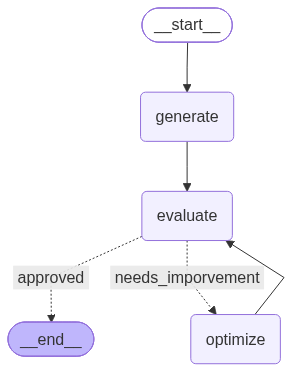

In [35]:
workflow

In [36]:
initial_state={
    "topic":"modi ji",
    "iteration":1,
    "max_iteration":5
}

result=workflow.invoke(initial_state)
result

{'topic': 'modi ji',
 'tweet': 'Modi ji’s speeches are like a Bollywood blockbuster: dramatic, full of promises, and the climax is always a new policy. The audience just waits for the popcorn, which is free, but the ticket price is a fresh tax. 🍿🚀',
 'evaluation': 'approved',
 'feedback': 'The tweet offers a fresh spin on a familiar political satire by likening Modi’s speeches to a Bollywood blockbuster, adding a clever tax‑popcorn twist that feels original enough to stand out. Its humor lands with a witty metaphor and emojis that boost shareability, and while it could be a touch tighter, it remains punchy enough to catch scrolling eyes. The format is spot‑on for Twitter—under 280 characters, no Q&A setup, and no weak filler—making it well‑suited for retweets and engagement.',
 'iteration': 1,
 'max_iteration': 5,
 'tweet_history': ['Modi ji’s speeches are like a Bollywood blockbuster: dramatic, full of promises, and the climax is always a new policy. The audience just waits for the po

In [37]:
for tweet in result['tweet_history']:
    print(tweet)

Modi ji’s speeches are like a Bollywood blockbuster: dramatic, full of promises, and the climax is always a new policy. The audience just waits for the popcorn, which is free, but the ticket price is a fresh tax. 🍿🚀
